#CafChem Teaching - SMILES primer.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MauricioCafiero/CafChem_Teaching_Notebooks/blob/main/notebooks/SMILES_primer_CafChem.ipynb)

## This notebook allows you to:
- See how SMILES represent molecules
- Try your own variations

## Requirements:
- CPU runtime
- needs RDKit installed if on Colab

### Only install on Colab

In [ ]:
!pip install rdkit

### Import libraries

In [1]:
import rdkit
from rdkit import Chem
from rdkit.Chem import Draw

## Basic SMILES rules
- Hydrogens implied unless explicitly defined (see below)
- Non-unique, but there are Canonical SMILES rules

## Basic SMILES characters

| Character | meaning |
| ---: | --- |
| **Atomic Symbol** | atom |
| C | regular carbon |
| c | aromatic carbon |
| N | nitrogen |
| **+ or -** | charge |
| **=** | double bond |
| **#** | triple bond |
| **stereochemistry** | |
| [C@@H] | clockwise stereochemistry |
| [C@H] | counterclockwise stereochemistry |
| F/C=C/F | *trans*-isomer |
| F/C=C\F | *cis*-isomer |
| **structure** | |
| **(...)** | inside () indicates a branch |
| C1 | number indicates start of ring |
| C1 again later | indicates closing of ring$^{1}$ |
| . | non-bonded (ionic) |
| **charges and groups** | |
| **[ ]** | to indicate charge / groups |
| [Na+] | sodium cation |
| [O-] | negative O |
| [Mg2+] | divalent magnesium |
| [NH3+] | charged amine |



$^{1}$If more than one ring in molecule, use 2, 3 ...



## Examples

### Alkanes, Alkenes, Alkynes

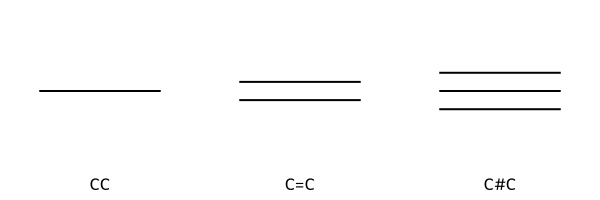

In [2]:
smiles = ["CC", "C=C", "C#C"]
mols = [Chem.MolFromSmiles(s) for s in smiles]

Chem.Draw.MolsToGridImage(mols, legends = smiles)

### Substituents

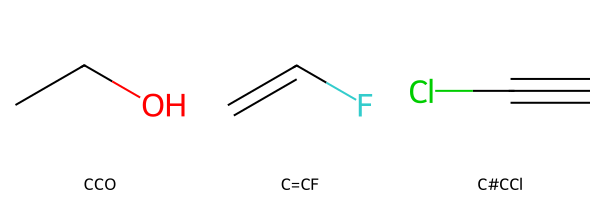

In [3]:
smiles = ["CCO", "C=CF", "C#CCl"]
mols = [Chem.MolFromSmiles(s) for s in smiles]

Chem.Draw.MolsToGridImage(mols, legends = smiles)

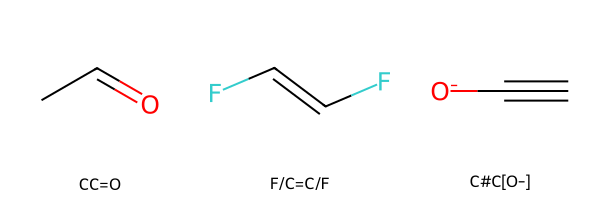

In [4]:
smiles = ["CC=O", "F/C=C/F", "C#C[O-]"]
mols = [Chem.MolFromSmiles(s) for s in smiles]

Chem.Draw.MolsToGridImage(mols, legends = smiles)

### Branches

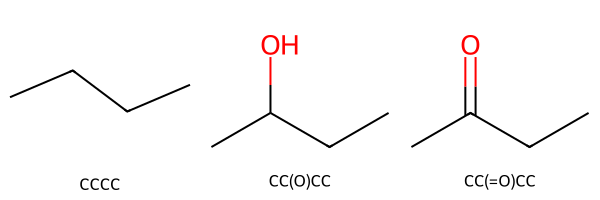

In [5]:
smiles = ["CCCC", "CC(O)CC", "CC(=O)CC"]
mols = [Chem.MolFromSmiles(s) for s in smiles]

Chem.Draw.MolsToGridImage(mols, legends = smiles)

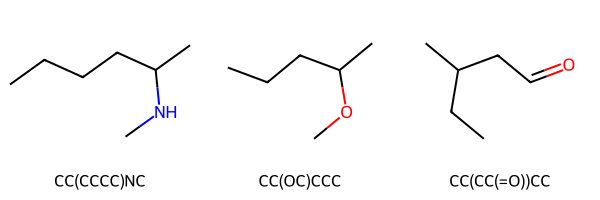

In [6]:
smiles = ["CC(CCCC)NC", "CC(OC)CCC", "CC(CC(=O))CC"]
mols = [Chem.MolFromSmiles(s) for s in smiles]

Chem.Draw.MolsToGridImage(mols, legends = smiles)

### Charges

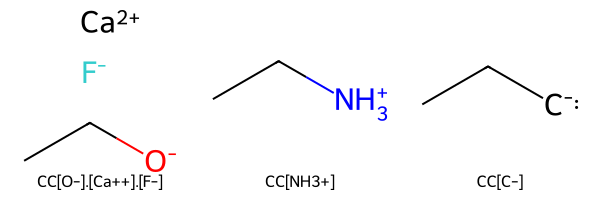

In [7]:
smiles = ["CC[O-].[Ca++].[F-]", "CC[NH3+]", "CC[C-]"]
mols = [Chem.MolFromSmiles(s) for s in smiles]

Chem.Draw.MolsToGridImage(mols, legends = smiles)

### Rings

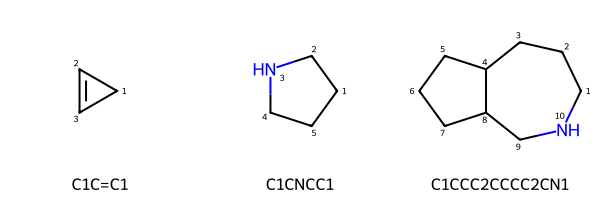

In [8]:
smiles = ["C1C=C1", "C1CNCC1", "C1CCC2CCCC2CN1"]
mols = [Chem.MolFromSmiles(s) for s in smiles]

for mol in mols:
  for atom in mol.GetAtoms():
    atom.SetProp("atomNote", str(atom.GetIdx()+1))

Chem.Draw.MolsToGridImage(mols, legends = smiles)

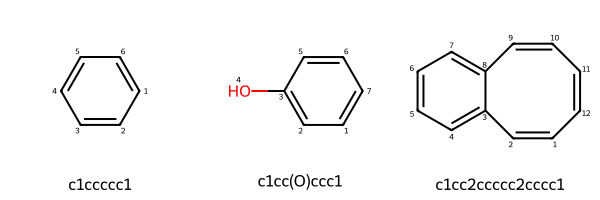

In [9]:
smiles = ["c1ccccc1", "c1cc(O)ccc1", "c1cc2ccccc2cccc1"]
mols = [Chem.MolFromSmiles(s) for s in smiles]

for mol in mols:
  for atom in mol.GetAtoms():
    atom.SetProp("atomNote", str(atom.GetIdx()+1))

Chem.Draw.MolsToGridImage(mols, legends = smiles)

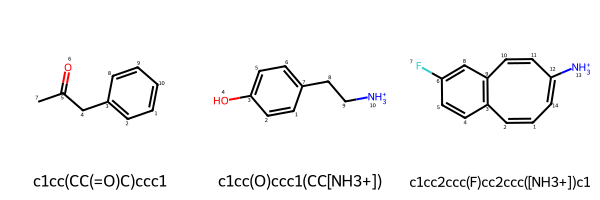

In [10]:
smiles = ["c1cc(CC(=O)C)ccc1", "c1cc(O)ccc1(CC[NH3+])", "c1cc2ccc(F)cc2ccc([NH3+])c1"]
mols = [Chem.MolFromSmiles(s) for s in smiles]

for mol in mols:
  for atom in mol.GetAtoms():
    atom.SetProp("atomNote", str(atom.GetIdx()+1))

Chem.Draw.MolsToGridImage(mols, legends = smiles)

### Real Molecules

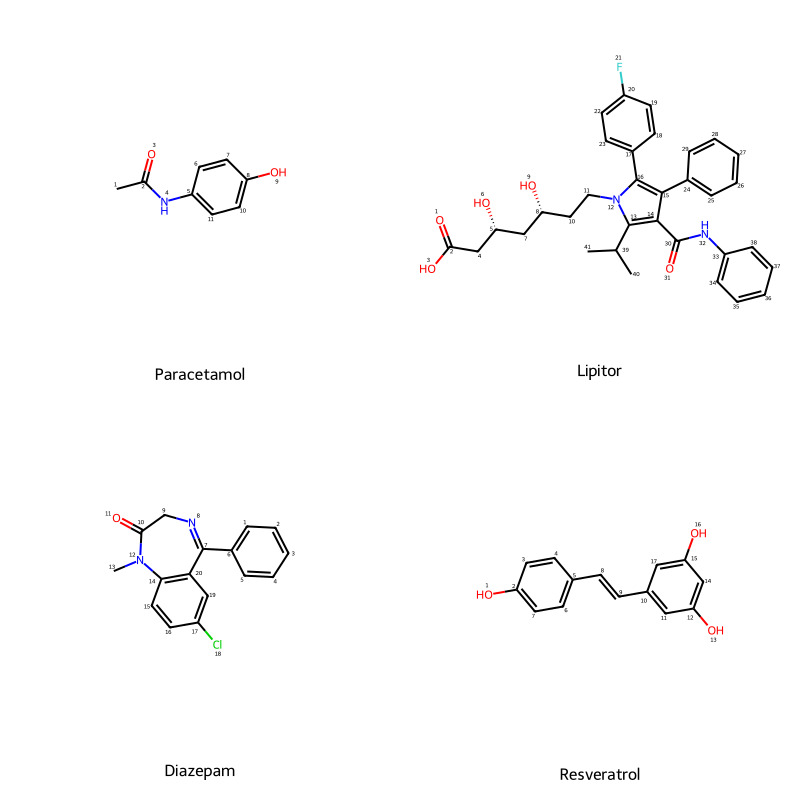

In [11]:
smiles = ["CC(=O)Nc1ccc(O)cc1", "O=C(O)C[C@H](O)C[C@H](O)CCn2c(c(c(c2c1ccc(F)cc1)c3ccccc3)C(=O)Nc4ccccc4)C(C)C",
             "c1ccccc1C2=NCC(=O)N(C)c3ccc(Cl)cc23", "Oc1ccc(cc1)/C=C/c2cc(O)cc(O)c2"]

names = ["Paracetamol", "Lipitor", "Diazepam", "Resveratrol"]
mols = [Chem.MolFromSmiles(s) for s in smiles]

for mol in mols:
  for atom in mol.GetAtoms():
    atom.SetProp("atomNote", str(atom.GetIdx()+1))

Chem.Draw.MolsToGridImage(mols, legends = names, subImgSize=(400,400), molsPerRow = 2)

## Run the cell below once and it will become interactive, changing the image as you change the SMILES string
- Interactivity only works on Colab

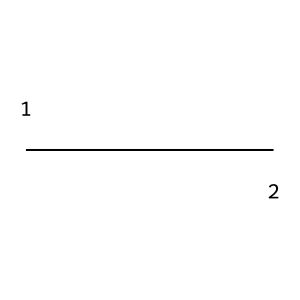

In [12]:
# @title Interactive SMILES. { run: "auto" }
SMILES = "CC" #@param {type:"string"}


mol = Chem.MolFromSmiles(SMILES)
for atom in mol.GetAtoms():
  atom.SetProp("atomNote", str(atom.GetIdx()+1))

Chem.Draw.MolToImage(mol)